# 02 · Fine-tuning method ablation

Full fine-tuning vs LoRA / rsLoRA (r = 16, 64) vs 4-bit QLoRA on `bert-base-uncased`, three seeds each. Test = 42 in-distribution sentences; challenge = 30 plain-English questions.

In [1]:
import json, os, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
from src.plotting import apply_style, hbar_groups, SERIES, MUTED, TEXT_SECONDARY
from src.preprocess import TextPreprocessor

apply_style()
pd.set_option("display.precision", 3)

def metrics(name):
    with open(os.path.join(ROOT, "results", "metrics", f"{name}.json"), encoding="utf-8") as f:
        return json.load(f)

def split(task, name):
    return TextPreprocessor.load_jsonl(os.path.join(ROOT, "data", "processed", task, f"{name}.jsonl"))

In [2]:
abl = metrics("classification_ablation")
rows = []
for name, runs in abl["runs"].items():
    for r in runs:
        rows.append({"variant": name, "seed": r["run_name"].rsplit("_s", 1)[1],
                     "test_acc": 100 * r["test"]["accuracy"], "challenge_acc": 100 * r["challenge"]["accuracy"],
                     "challenge_f1": r["challenge"]["macro_f1"], "trainable_params": r["trainable_params"],
                     "peak_gpu_mib": r["peak_gpu_mib"], "epochs": r["epochs_run"]})
runs = pd.DataFrame(rows)
summary = runs.groupby("variant", sort=False).agg(
    test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
    challenge_mean=("challenge_acc", "mean"), challenge_std=("challenge_acc", "std"),
    trainable_params=("trainable_params", "first"), peak_gpu_mib=("peak_gpu_mib", "mean"))
summary

,test_mean,test_std,challenge_mean,challenge_std,trainable_params,peak_gpu_mib
variant,,,,,,
full_ft,98.413,2.749,72.222,22.194,109484547,2114.900
lora_r16,97.619,2.381,63.333,12.019,592131,686.700
rslora_r16,96.825,3.637,68.889,22.690,592131,686.700
lora_r64,96.825,3.637,61.111,16.443,2361603,710.800
rslora_r64,97.619,0.000,74.444,10.184,2361603,710.800
qlora_r16,98.413,1.375,72.222,5.092,592131,312.667


## Accuracy by method (mean ± std over 3 seeds)

The grey reference line is the TF-IDF + logistic-regression baseline on the challenge set.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


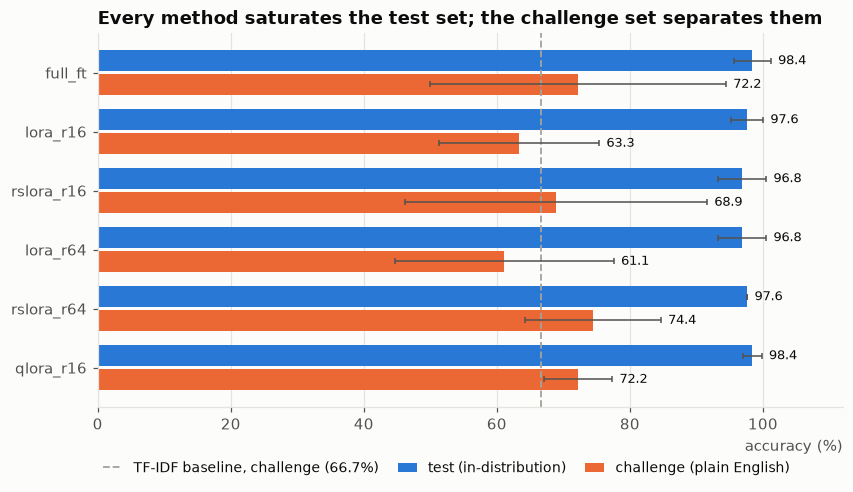

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.6))
base = 100 * abl["baseline"]["challenge"]["accuracy"]
ax.axvline(base, color=MUTED, linestyle="--", linewidth=1.2, label=f"TF-IDF baseline, challenge ({base:.1f}%)")
hbar_groups(ax, list(summary.index),
            {"test (in-distribution)": summary["test_mean"].tolist(), "challenge (plain English)": summary["challenge_mean"].tolist()},
            errors={"test (in-distribution)": summary["test_std"].tolist(), "challenge (plain English)": summary["challenge_std"].tolist()},
            xlabel="accuracy (%)", xlim=(0, 112))
ax.set_title("Every method saturates the test set; the challenge set separates them")
fig.tight_layout()

## Seed-to-seed spread

Each dot is one seed. The spread is wider than most gaps between methods, which is why no single-seed comparison is reported.

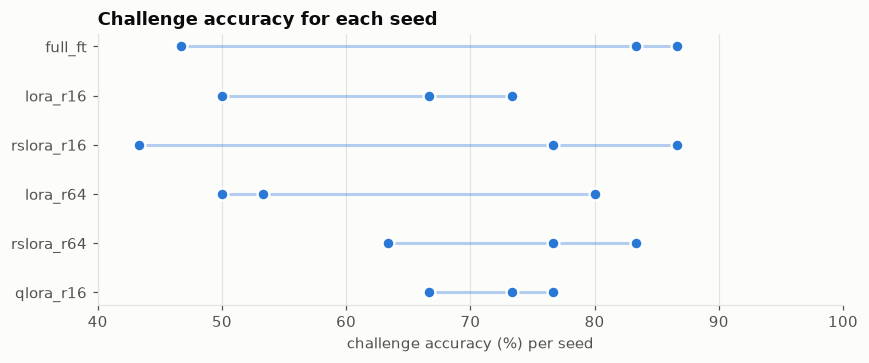

In [4]:
order = list(summary.index)
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, v in enumerate(order):
    vals = runs.loc[runs.variant == v, "challenge_acc"].to_numpy()
    ax.scatter(vals, [i] * len(vals), s=60, color=SERIES[0], edgecolor="white", linewidth=1.5, zorder=3)
    ax.plot([vals.min(), vals.max()], [i, i], color=SERIES[0], alpha=0.35, linewidth=2)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlim(40, 100)
ax.set_xlabel("challenge accuracy (%) per seed")
ax.set_title("Challenge accuracy for each seed")
fig.tight_layout()

## Cost: trainable parameters and peak GPU memory

,trainable_params,peak_gpu_mib,trainable_%
variant,,,
full_ft,109484547,2114.900,100.000
lora_r16,592131,686.700,0.541
rslora_r16,592131,686.700,0.541
lora_r64,2361603,710.800,2.157
rslora_r64,2361603,710.800,2.157
qlora_r16,592131,312.667,0.541


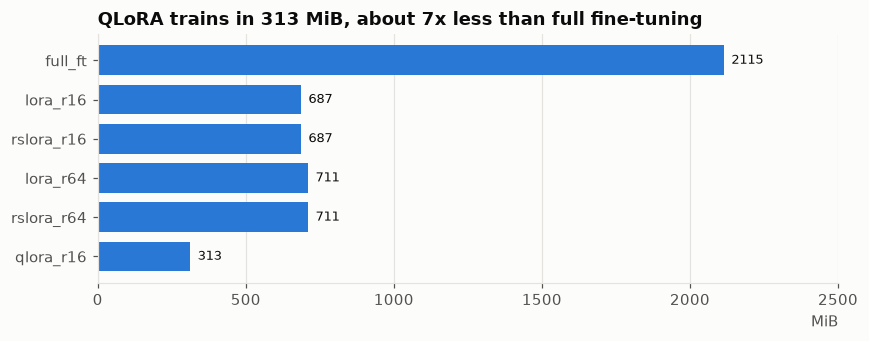

In [5]:
cost = summary[["trainable_params", "peak_gpu_mib"]].copy()
cost["trainable_%"] = 100 * cost["trainable_params"] / runs.loc[runs.variant == "full_ft", "trainable_params"].iloc[0]
fig, ax = plt.subplots(figsize=(8, 3.2))
hbar_groups(ax, list(cost.index), {"peak GPU memory (MiB)": cost["peak_gpu_mib"].tolist()}, fmt="{:.0f}",
            xlabel="MiB", xlim=(0, 2500))
ax.set_title("QLoRA trains in 313 MiB, about 7x less than full fine-tuning")
fig.tight_layout()
cost